# 02 Draw the toy graph

Draws the toy knowledge graph from files that `01_explore_openalex.ipynb` has already written. Run notebook 01 first, so that `data/output/mentions.csv` is up to date.

How to read the picture (the same text is in the legend on the figure):

- **Node** = one item: a quantity (illuminance), a unit (lx), an instrument or method (Sky Quality Meter), a user group (ecologists), and so on.
- **Fill colour** = the item's **class**, i.e. what kind of thing it is.
- **Outline** = where the item comes from. Dark outline: it is in the curated seed graph (`kg/seed_statements.csv`, from the Dickerson table). Purple outline: it was only found by mining paper abstracts (`data/output/mentions.csv`).
- **Size** = how many papers mention the item (items nobody mentioned have a fixed small size).
- **Solid grey arrow** = a curated statement, with the property written on it (for example *illuminance reported_in lx*).
- **Dashed purple arrow** = "papers mention this item". It starts at the grey square, which stands for all the papers. Thicker = more papers.

Topic words such as conservation or tourism show up as items with class *other*. They are topics, not measurement items.

Needs `pandas`, `networkx` and `matplotlib`.

In [1]:
import textwrap
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

TOP_N = 12            # how many mined items to draw (most papers first)
SKIP_BROAD = False    # True = leave out broad matches

# Curated items to draw. None = the whole seed graph.
SEED_ITEMS = None
# Statement types to draw. None = all of them.
SEED_PROPERTIES = None

# Items to leave out of the mined layer (for example topic words)
HIDE_MINED = []       # e.g. ["conservation", "regulation", "urban planning"]

LAYOUT_SEED = 4       # change for a different arrangement

## 1. Load the files and work out each item's class

In [2]:
seed = pd.read_csv("../kg/seed_statements.csv")
items = pd.read_csv("../kg/items.csv")
mentions = pd.read_csv("../data/output/mentions.csv")
if SKIP_BROAD:
    mentions = mentions[mentions["match"] == "exact"]
if SEED_ITEMS is not None:
    seed = seed[seed["subject"].isin(SEED_ITEMS)]
if SEED_PROPERTIES is not None:
    seed = seed[seed["property"].isin(SEED_PROPERTIES)]

# class of each item: from items.csv; units and user groups from how they are used;
# methods from the mined table; everything else is "other"
item_class = dict(zip(items["item"], items["class"]))
for r in seed.itertuples():
    if r.property == "reported_in":
        item_class.setdefault(r.object, "unit")
    if r.property == "used_by":
        item_class.setdefault(r.object, "user group")
for r in mentions.dropna(subset=["item_class"]).itertuples():
    item_class.setdefault(r.item, r.item_class)

papers_per_item = mentions.groupby("item")["paper"].nunique()
print(len(seed), "curated statements;", len(mentions), "mentions from",
      mentions["paper"].nunique(), "papers")
pd.Series(item_class).value_counts()

40 curated statements; 1069 mentions from 668 papers


discipline       21
method           12
unit              9
quantity          8
user group        7
spectral band     2
instrument        1
Name: count, dtype: int64

## 2. Build the graph

In [3]:
G = nx.DiGraph()

# curated layer
for r in seed.itertuples():
    G.add_node(r.subject, origin="seed")
    G.add_node(r.object, origin="seed")
    G.add_edge(r.subject, r.object, label=r.property, kind="seed")

# mined layer: the items with the most papers, linked to one hub node
top = papers_per_item.drop(HIDE_MINED, errors="ignore").sort_values(ascending=False).head(TOP_N)
HUB = "all papers"
G.add_node(HUB, origin="hub")
for item, n in top.items():
    if item not in G:
        G.add_node(item, origin="mined")
    G.add_edge(HUB, item, kind="mined", papers=int(n))

print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")
top

37 nodes, 52 edges


item
conservation      232
regulation        106
ecology            99
lx                 95
satellite          68
radiance           43
night sky          41
urban planning     37
remote sensing     36
illuminance        35
skyglow            22
tourism            22
Name: paper, dtype: int64

## 3. Draw it

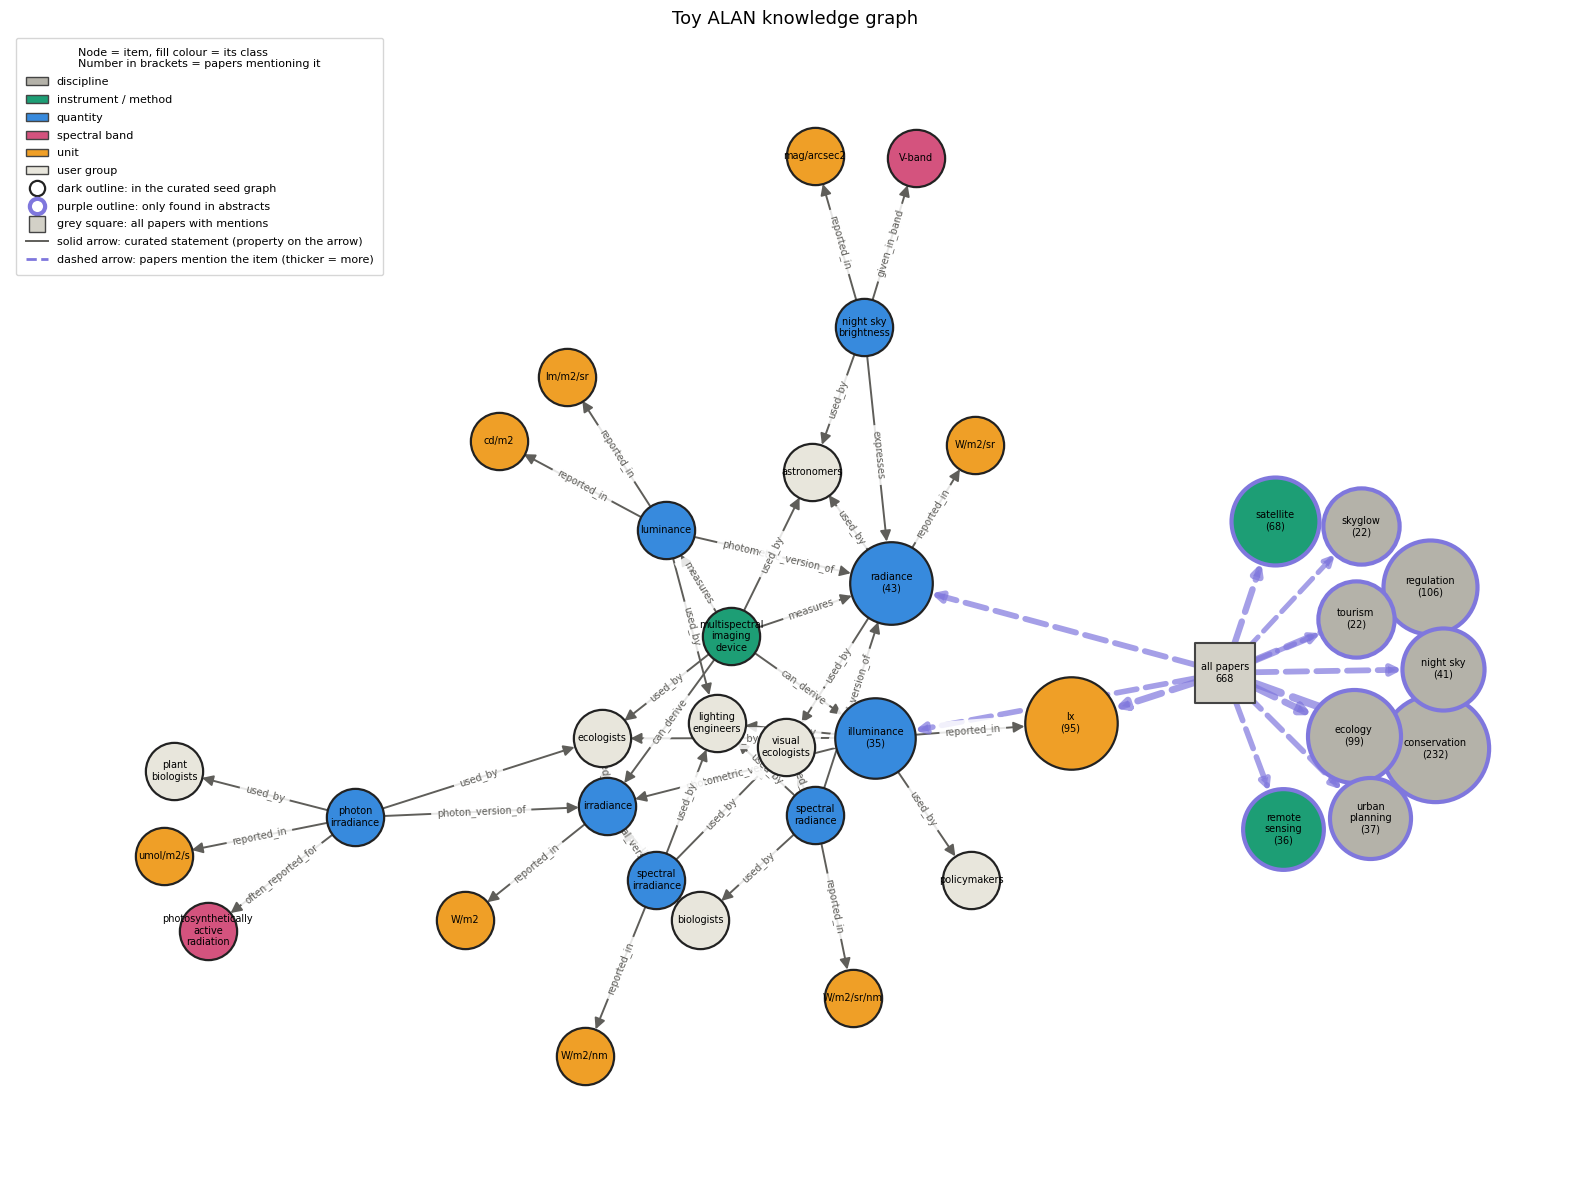

In [4]:
class_colours = {
    "quantity":      "#378ADD",
    "unit":          "#EF9F27",
    "instrument / method": "#1D9E75",
    "discipline":    "#B4B2A9",
    "spectral band": "#D4537E",
    "user group":    "#E8E6DC",
    "other":         "#B4B2A9",
}
SEED_EDGE, MINED_EDGE = "#5F5E5A", "#7F77DD"

def cls(n):
    c = item_class.get(n, "other")
    return "instrument / method" if c in ("instrument", "method") else c

def size(n):
    if n == HUB:
        return 1900
    papers = papers_per_item.get(n, 0)
    return 1700 + 280 * np.sqrt(papers) if n in top.index else 1700

def label(n):
    if n == HUB:
        return f"all papers\n{mentions['paper'].nunique():,}"
    text = textwrap.fill(n, 12, break_long_words=False)
    return f"{text}\n({int(top[n])})" if n in top.index else text

# layout: spring layout, edge weight pulls linked items together
H = G.to_undirected()
pos = nx.spring_layout(H, k=1.3 / np.sqrt(len(H)), seed=LAYOUT_SEED, iterations=400)

fig, ax = plt.subplots(figsize=(16, 12))

# edges
seed_edges = [(u, v) for u, v, d in G.edges(data=True) if d["kind"] == "seed"]
mined_edges = [(u, v) for u, v, d in G.edges(data=True) if d["kind"] == "mined"]
nx.draw_networkx_edges(G, pos, edgelist=seed_edges, edge_color=SEED_EDGE, width=1.4,
                       arrows=True, arrowsize=16, node_size=[size(n) for n in G], ax=ax)
widths = [0.8 + 0.9 * np.log1p(G.edges[e]["papers"]) for e in mined_edges]
nx.draw_networkx_edges(G, pos, edgelist=mined_edges, edge_color=MINED_EDGE, width=widths,
                       style="dashed", alpha=0.7, arrows=True, arrowsize=14,
                       node_size=[size(n) for n in G], ax=ax)
nx.draw_networkx_edge_labels(G, pos, {(u, v): G.edges[u, v]["label"] for u, v in seed_edges},
                             font_size=7, font_color=SEED_EDGE,
                             bbox=dict(fc="white", ec="none", alpha=0.85), ax=ax)

# nodes (fill = class, outline = origin)
for n in G:
    if n == HUB:
        nx.draw_networkx_nodes(G, pos, nodelist=[n], node_shape="s", node_size=size(n),
                               node_color="#D3D1C7", edgecolors="#444", linewidths=1.5, ax=ax)
        continue
    outline = "#222" if G.nodes[n]["origin"] == "seed" else MINED_EDGE
    lw = 1.6 if G.nodes[n]["origin"] == "seed" else 3.0
    nx.draw_networkx_nodes(G, pos, nodelist=[n], node_size=size(n),
                           node_color=class_colours.get(cls(n), "#B4B2A9"),
                           edgecolors=outline, linewidths=lw, ax=ax)
nx.draw_networkx_labels(G, pos, labels={n: label(n) for n in G}, font_size=7, ax=ax)

# legend
present = sorted({cls(n) for n in G if n != HUB})
handles = [Patch(fc=class_colours.get(c, "#B4B2A9"), ec="#444", label=c) for c in present]
handles += [
    Line2D([], [], marker="o", ls="", mfc="white", mec="#222", mew=1.6, ms=11,
           label="dark outline: in the curated seed graph"),
    Line2D([], [], marker="o", ls="", mfc="white", mec=MINED_EDGE, mew=3, ms=11,
           label="purple outline: only found in abstracts"),
    Line2D([], [], marker="s", ls="", mfc="#D3D1C7", mec="#444", ms=11,
           label="grey square: all papers with mentions"),
    Line2D([], [], color=SEED_EDGE, lw=1.4,
           label="solid arrow: curated statement (property on the arrow)"),
    Line2D([], [], color=MINED_EDGE, lw=2, ls="--",
           label="dashed arrow: papers mention the item (thicker = more)"),
]
leg = ax.legend(handles=handles, loc="upper left", fontsize=8, frameon=True,
                title="Node = item, fill colour = its class\nNumber in brackets = papers mentioning it",
                title_fontsize=8, borderpad=0.9, labelspacing=0.7)
ax.set_title("Toy ALAN knowledge graph", fontsize=13)
ax.margins(0.08)
ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Save the picture (optional)

In [5]:
# fig.savefig("../data/output/alan_toy_graph.png", dpi=150, bbox_inches="tight")